# 03 · B1: quan el símptoma apunta a la bateria, ho és?

Dels mòbils que arriben amb un símptoma típic de bateria (no carrega, dura poc, no s'encén, inflada), quina avaria hi van trobar els voluntaris?

- Només MobiFix: el tipus d'avaria l'han posat persones, no el classificador. No cal cap revisió manual.
- Els símptomes es detecten amb paraules clau (`comu.SIMPTOMES`). Molts textos ja inclouen el diagnòstic («bateria canviada»), i això infla la bateria. L'estimació principal es fa amb els textos que **no** diuen «bateria».

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import comu

rng = np.random.default_rng(42)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
BATERIA, PANTALLA, GRIS = "#eb6834", "#2a78d6", "#8f8e89"

# Tipus d'avaria més detallat que comu.GRUPS: aquí volem separar bateria, carregador i port
DETALL = {"Power/battery": "Bateria", "Charger": "Carregador", "USB/charging port": "Port de càrrega",
          "Screen": "Pantalla", "Unknown": "Desconegut"}
PROGRAMARI = {"Software update", "Software issue", "Stuck booting", "Storage problem",
              "Help/configuration", "Performance", "Access issue"}

mobifix = comu.carrega_mobifix()
mobifix = mobifix[mobifix["problem"].notna()].copy()
mobifix["avaria"] = mobifix["fault_type"].map(DETALL)
mobifix.loc[mobifix["fault_type"].isin(PROGRAMARI), "avaria"] = "Programari"
mobifix["avaria"] = mobifix["avaria"].fillna("Altres")
mobifix = pd.concat([mobifix, comu.simptomes(mobifix["problem"])], axis=1)
print(f"Reparacions de MobiFix amb text: {len(mobifix):,}")
mobifix[list(comu.SIMPTOMES) + ["algun_simptoma", "mencio_bateria"]].sum()

Reparacions de MobiFix amb text: 1,664


no_carrega         52
dura_poc           10
no_sencen          50
inflada             4
algun_simptoma    114
mencio_bateria    187
dtype: int64

## Quina avaria hi ha darrere de cada símptoma

In [2]:
ORDRE = ["Bateria", "Carregador", "Port de càrrega", "Programari", "Pantalla", "Altres", "Desconegut"]

def darrere(df):
    files = {}
    for nom in list(comu.SIMPTOMES) + ["algun_simptoma"]:
        sub = df[df[nom]]
        files[nom] = sub["avaria"].value_counts(normalize=True).reindex(ORDRE, fill_value=0)
        files[nom]["n"] = len(sub)
    return pd.DataFrame(files).T

tots = darrere(mobifix)
sense_diagnostic = darrere(mobifix[~mobifix["mencio_bateria"]])
print("Tots els textos amb el símptoma:")
display(tots.round(2))
print("Només els que no diuen 'bateria' (estimació principal):")
sense_diagnostic.round(2)

Tots els textos amb el símptoma:


avaria,Bateria,Carregador,Port de càrrega,Programari,Pantalla,Altres,Desconegut,n
no_carrega,0.56,0.04,0.31,0.00,0.02,0.00,0.08,52.0
dura_poc,0.80,0.00,0.00,0.00,0.10,0.10,0.00,10.0
no_sencen,0.64,0.02,0.00,0.08,0.06,0.06,0.14,50.0
inflada,1.00,0.00,0.00,0.00,0.00,0.00,0.00,4.0
algun_simptoma,0.62,0.03,0.14,0.04,0.04,0.04,0.10,114.0


Només els que no diuen 'bateria' (estimació principal):


avaria,Bateria,Carregador,Port de càrrega,Programari,Pantalla,Altres,Desconegut,n
no_carrega,0.50,0.05,0.33,0.00,0.02,0.00,0.10,42.0
dura_poc,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
no_sencen,0.57,0.02,0.00,0.10,0.07,0.07,0.17,42.0
inflada,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
algun_simptoma,0.53,0.04,0.17,0.05,0.05,0.04,0.13,83.0


## Figura 1

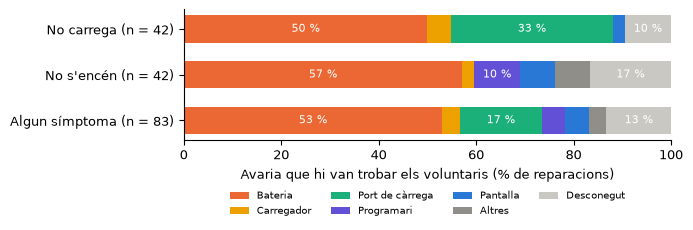

In [3]:
NOMS = {"no_carrega": "No carrega", "no_sencen": "No s'encén", "algun_simptoma": "Algun símptoma"}
COLORS = {"Bateria": BATERIA, "Carregador": "#eda100", "Port de càrrega": "#1baf7a", "Programari": "#6250d6",
          "Pantalla": PANTALLA, "Altres": GRIS, "Desconegut": "#c9c8c2"}
t = sense_diagnostic.loc[list(NOMS)]
etiquetes = [f"{NOMS[i]} (n = {int(t.loc[i, 'n'])})" for i in t.index]

fig, ax = plt.subplots(figsize=(7, 2.6))
esquerra = np.zeros(len(t))
for avaria in ORDRE:
    valors = t[avaria].to_numpy() * 100
    ax.barh(etiquetes, valors, left=esquerra, color=COLORS[avaria], label=avaria, height=0.6)
    for y, (x0, v) in enumerate(zip(esquerra, valors)):
        if v >= 8:
            ax.text(x0 + v / 2, y, f"{v:.0f} %", ha="center", va="center", color="white", fontsize=8)
    esquerra += valors
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Avaria que hi van trobar els voluntaris (% de reparacions)")
ax.legend(ncol=4, fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout()
fig.savefig(comu.POST / "b1_simptomes.png", dpi=200, bbox_inches="tight")
plt.show()

## Comprovació a mà de les paraules clau

Una mostra de 30 textos amb algun símptoma: cal llegir-los i comprovar que el símptoma detectat és correcte.

In [4]:
cols = list(comu.SIMPTOMES) + ["avaria", "problem"]
mostra = mobifix[mobifix["algun_simptoma"]].sample(30, random_state=42)[cols]
with pd.option_context("display.max_colwidth", 120):
    display(mostra)

,no_carrega,dura_poc,no_sencen,inflada,avaria,problem
1450,False,False,True,False,Bateria,Nach einem Sturz zeigte ein „S60“ Smartphone von Doogee auf einmal keine Funktion mehr. Es ließ sich nicht einschalt...
55,True,False,False,False,Port de càrrega,Doesn't charge
680,True,False,False,False,Bateria,Accu laadt niet op ~ Loszittende accu
1219,False,False,True,False,Desconegut,Won't turn on
124,True,False,True,False,Bateria,Not charging. won't turn on. Advice given.
809,False,True,False,False,Bateria,batterij loop snel leeg ~ ouderdom
1249,False,False,True,False,Bateria,Doesn't turn on: tested and it charges. Opened it: the power button is very hard to press but everything works.
1158,True,False,False,False,Bateria,Does not charge plus other damage
849,False,True,False,False,Bateria,Battery drains really fast
139,True,False,False,False,Bateria,"Doesn't charge, doesn't switch on. Needs new battery."
